
# **NeuraSight – `vision-engine-v2.ipynb`**

**Known modules in this version:**
- Gaussian smoothing
- Canny edges 
- Harris corners 
- Descriptors 
- Matching 
- RANSAC homography 


## 1) Imports & Setup

In [219]:

import os, math, random, time
from typing import List, Tuple
import numpy as np
import cv2
import matplotlib.pyplot as plt
%matplotlib inline

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)


OpenCV: 4.12.0
NumPy: 2.2.6


## 2) Data Paths

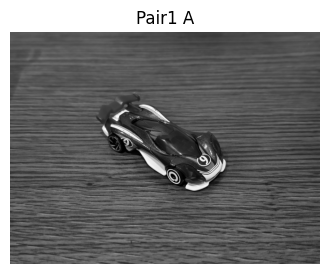

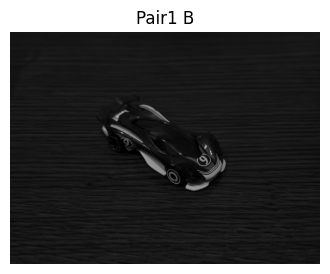

In [220]:

IMG_A_1 = './dataset/pair1_A.jpg'  # normal
IMG_B_1 = './dataset/pair1_B.jpg'  # dimmed
IMG_A_2 = './dataset/pair2_A.jpg'  # side view
IMG_B_2 = './dataset/pair2_B.jpg'  # front view
IMG_A_3 = './dataset/pair3_A.jpg'  # closeup
IMG_B_3 = './dataset/pair3_B.jpg'  # far away

def load_gray(path: str) -> np.ndarray:
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    assert img is not None, f"Image not found: {path}"
    return img

def show(img, title=None):
    plt.figure(figsize=(4,4))
    if img.ndim == 2:
        plt.imshow(img, cmap='gray')
    else:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    if title: plt.title(title)
    plt.axis('off'); plt.show()

# Visualization
A1 = load_gray(IMG_A_1)
B1 = load_gray(IMG_B_1)

show(A1, "Pair1 A")
show(B1, "Pair1 B")


## 3) Gaussian Smoothing

In [221]:

def gaussian_kernel_buggy(size: int, sigma: float) -> np.ndarray:
    """
    Buggy version errors:
    1. Missing sigma squared in the denominator
    2. No normalization
    """
    ax = np.arange(-(size//2), size//2 + 1)
    xx, yy = np.meshgrid(ax, ax)
    
    kernel = np.exp(-(xx**2 + yy**2) / (2 * sigma))
    
    return kernel.astype(np.float32)

def gaussian_kernel(size: int, sigma: float) -> np.ndarray:
    """
    Fixed version
    G(x,y) = (1/(2πσ²)) * exp(-(x²+y²)/(2σ²))
    """
    ax = np.arange(-(size//2), size//2 + 1)
    xx, yy = np.meshgrid(ax, ax)

    kernel = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    kernel = kernel / np.sum(kernel)

    return kernel.astype(np.float32)

def convolve(img: np.ndarray, k: np.ndarray) -> np.ndarray:
    return cv2.filter2D(img, -1, k)


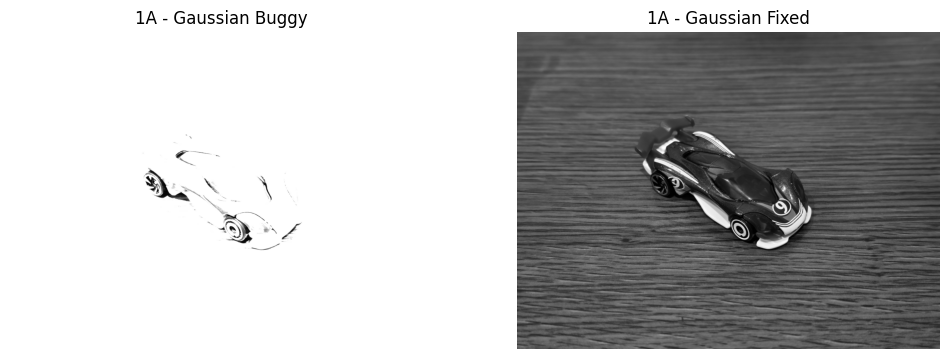

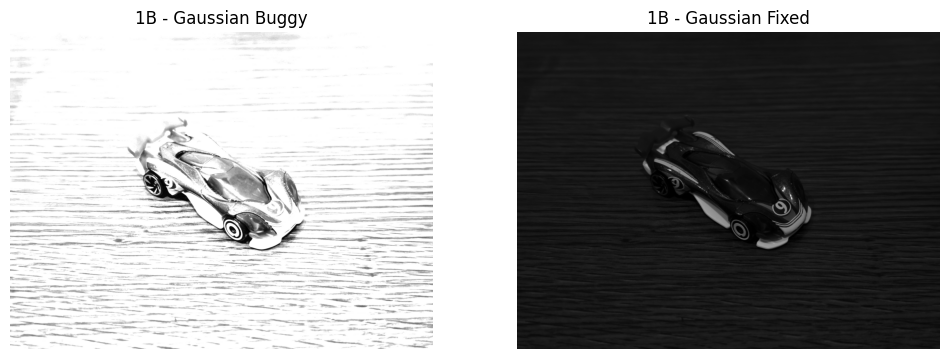

In [222]:

# Visualization
A1_smooth_buggy = convolve(A1, gaussian_kernel_buggy(7, 2.0))
B1_smooth_buggy = convolve(B1, gaussian_kernel_buggy(7, 2.0))

A1_smooth = convolve(A1, gaussian_kernel(7, 2.0))
B1_smooth = convolve(B1, gaussian_kernel(7, 2.0))

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("1A - Gaussian Buggy")
plt.imshow(A1_smooth_buggy, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("1A - Gaussian Fixed")
plt.imshow(A1_smooth, cmap='gray')
plt.axis('off')
plt.show()

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("1B - Gaussian Buggy")
plt.imshow(B1_smooth_buggy, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("1B - Gaussian Fixed")
plt.imshow(B1_smooth, cmap='gray')
plt.axis('off')
plt.show()


In [223]:

print("Quantitative Analysis: Buggy vs Fixed Gaussian Kernel\n")

size, sigma = 7, 2.0
kernel_buggy = gaussian_kernel_buggy(size, sigma)
kernel_fixed = gaussian_kernel(size, sigma)

# Quantitative metrics
print(f"Kernel size: {size}x{size}, sigma = {sigma}\n")

print(f"{'Metric':<25} {'Buggy Kernel':<20} {'Fixed Kernel':<20}")
print("-"*60)
print(f"{'Sum (should be 1.0):':<25} {kernel_buggy.sum():<20.6f} {kernel_fixed.sum():<20.6f}")
print(f"{'Max value:':<25} {kernel_buggy.max():<20.6f} {kernel_fixed.max():<20.6f}")
print(f"{'Min value:':<25} {kernel_buggy.min():<20.6f} {kernel_fixed.min():<20.6f}")
print(f"{'Center value:':<25} {kernel_buggy[size//2, size//2]:<20.6f} {kernel_fixed[size//2, size//2]:<20.6f}")
print(f"{'Std deviation:':<25} {kernel_buggy.std():<20.6f} {kernel_fixed.std():<20.6f}\n")

print(f"Denominator comparison for sigma={sigma}:")
print(f"Buggy: 2 x sigma = 2 x {sigma} = {2*sigma}")
print(f"Fixed: 2 x sigma² = 2 x {sigma}² = {2*sigma**2}")
print(f"Ratio: {(2*sigma**2)/(2*sigma):.1f}x difference in spread")


Quantitative Analysis: Buggy vs Fixed Gaussian Kernel

Kernel size: 7x7, sigma = 2.0

Metric                    Buggy Kernel         Fixed Kernel        
------------------------------------------------------------
Sum (should be 1.0):      12.279130            1.000000            
Max value:                1.000000             0.046702            
Min value:                0.011109             0.004922            
Center value:             1.000000             0.046702            
Std deviation:            0.255659             0.011405            

Denominator comparison for sigma=2.0:
Buggy: 2 x sigma = 2 x 2.0 = 4.0
Fixed: 2 x sigma² = 2 x 2.0² = 8.0
Ratio: 2.0x difference in spread


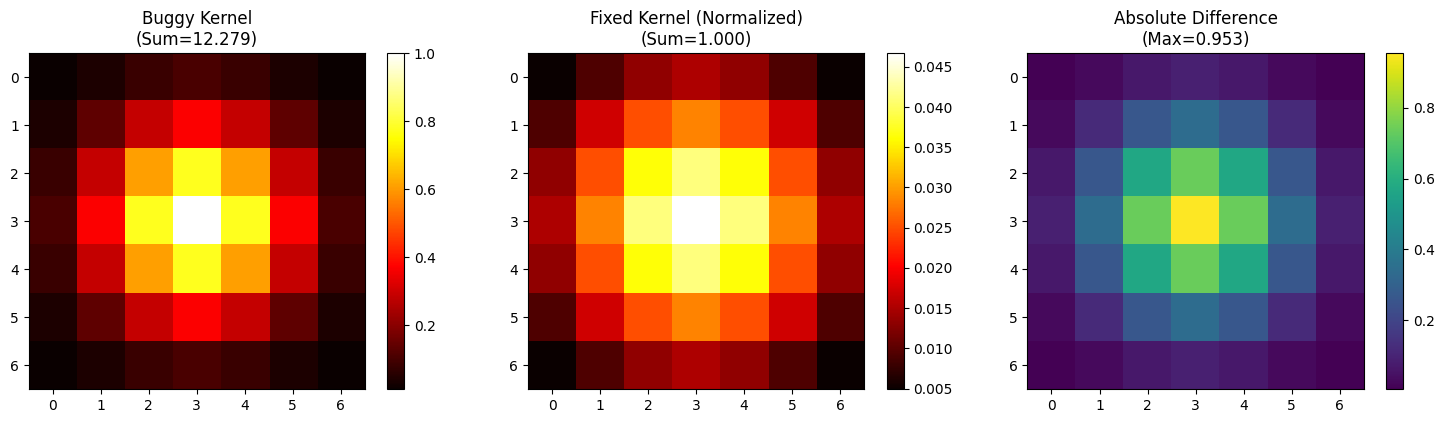

In [224]:

# Kernel Visualization
plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1)
im1 = plt.imshow(kernel_buggy, cmap='hot', interpolation='nearest')
plt.title(f'Buggy Kernel\n(Sum={kernel_buggy.sum():.3f})')
plt.colorbar(im1)

plt.subplot(1, 3, 2)
im2 = plt.imshow(kernel_fixed, cmap='hot', interpolation='nearest')
plt.title(f'Fixed Kernel (Normalized)\n(Sum={kernel_fixed.sum():.3f})')
plt.colorbar(im2)

diff_kernel = np.abs(kernel_buggy - kernel_fixed)
plt.subplot(1, 3, 3)
im3 = plt.imshow(diff_kernel, cmap='viridis', interpolation='nearest')
plt.title(f'Absolute Difference\n(Max={diff_kernel.max():.3f})')
plt.colorbar(im3)

plt.tight_layout()
plt.show()


## 4) Edge Detection (Canny)

In [225]:

def canny_buggy(img: np.ndarray, low: int=150, high: int=50) -> np.ndarray:
    """Buggy version with swapped thresholds"""
    return cv2.Canny(img, threshold1=high, threshold2=low)

def canny(img: np.ndarray, low: int=50, high: int=150) -> np.ndarray:
    """
    Canny uses double thresholding for hysteresis:
    - Pixels > high_threshold -> strong edges (kept)
    - Pixels > low_threshold -> weak edges (kept only if connected to strong)
    - Pixels < low_threshold -> suppressed
    """
    return cv2.Canny(img, threshold1=low, threshold2=high)


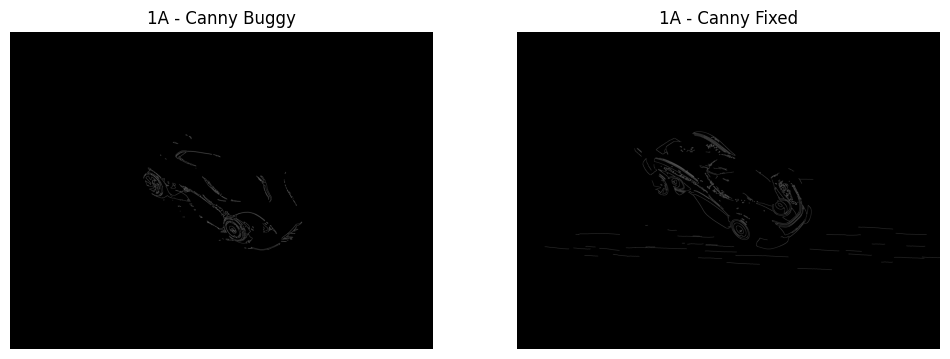

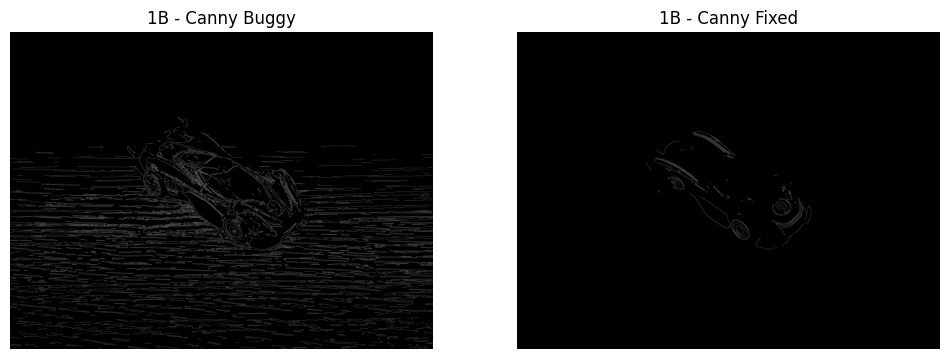

In [226]:

# Visualization
E_A1_buggy = canny_buggy(A1_smooth_buggy)
E_B1_buggy = canny_buggy(B1_smooth_buggy)

E_A1 = canny(A1_smooth)
E_B1 = canny(B1_smooth)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("1A - Canny Buggy")
plt.imshow(E_A1_buggy, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("1A - Canny Fixed")
plt.imshow(E_A1, cmap='gray')
plt.axis('off')
plt.show()

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("1B - Canny Buggy")
plt.imshow(E_B1_buggy, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("1B - Canny Fixed")
plt.imshow(E_B1, cmap='gray')
plt.axis('off')
plt.show()


In [227]:

print("Quantitative Analysis: Buggy vs Fixed Canny Edge Detection\n")

E_A1_buggy_count = np.count_nonzero(E_A1_buggy)
E_B1_buggy_count = np.count_nonzero(E_B1_buggy)

E_A1_count = np.count_nonzero(E_A1)
E_B1_count = np.count_nonzero(E_B1)

print(f"1A Canny Edge Counts: {E_A1_buggy_count} (Buggy) vs {E_A1_count} (Fixed)")
print(f"1B Canny Edge Counts: {E_B1_buggy_count} (Buggy) vs {E_B1_count} (Fixed)")


Quantitative Analysis: Buggy vs Fixed Canny Edge Detection

1A Canny Edge Counts: 24933 (Buggy) vs 45311 (Fixed)
1B Canny Edge Counts: 346481 (Buggy) vs 19283 (Fixed)


## 5) Harris Corners

In [228]:

def harris_response_buggy(img: np.ndarray, block=2, ksize=3, k=0.04):
    """Buggy version without normalization"""
    img32 = np.float32(img)
    R = cv2.cornerHarris(img32, block, ksize, k)
    
    return R

def harris_response(img: np.ndarray, block=2, ksize=3, k=0.04):
    """Fixed version with normalization of response values to [0, 1]"""
    img32 = np.float32(img)
    R = cv2.cornerHarris(img32, block, ksize, k)
    Rn = cv2.normalize(R, None, alpha=0, beta=1, norm_type=cv2.NORM_MINMAX)

    return Rn

def harris_kps_buggy(R: np.ndarray, thresh: float=1e7) -> List[cv2.KeyPoint]:
    """Buggy version with a fixed high threshold"""
    ys, xs = np.where(R > thresh)
    return [cv2.KeyPoint(float(x), float(y), 3) for (y, x) in zip(ys, xs)]

def harris_kps(R: np.ndarray, thresh: float=0.01, max_kps: int=500) -> List[cv2.KeyPoint]:
    """
    Harris keypoint extraction with adaptive threshold and non-maximum suppression.
    """
    thresh = thresh * R.max()
    R_thresh = np.zeros_like(R)
    R_thresh[R > thresh] = R[R > thresh]

    R_dilated = cv2.dilate(R_thresh, None)
    local_max = (R_thresh == R_dilated)
    ys, xs = np.where(local_max & (R_thresh > 0))

    strengths = R[ys, xs]
    sorted_idx = np.argsort(-strengths)
    if max_kps is not None:
        sorted_idx = sorted_idx[:max_kps]

    kps = [cv2.KeyPoint(float(xs[i]), float(ys[i]), 3) for i in sorted_idx]
    return kps


Harris Keypoints Detected:
Buggy kpsA: 25 kpsB: 7
Fixed kpsA: 500 kpsB: 500


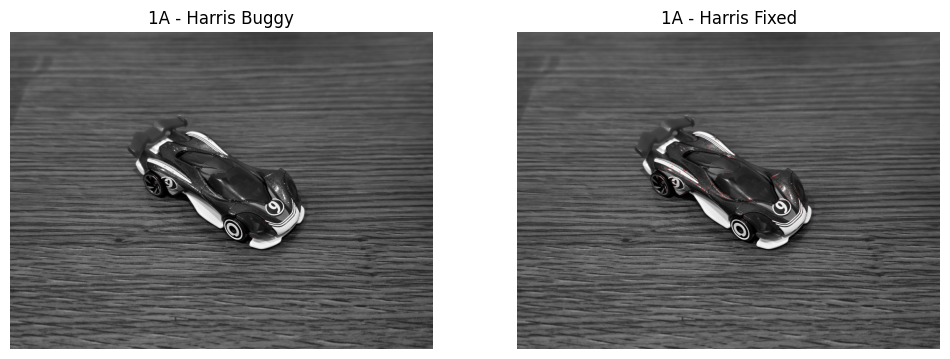

In [229]:

# Visualization
R_A1_buggy = harris_response_buggy(A1_smooth_buggy)
R_B1_buggy = harris_response_buggy(B1_smooth_buggy)
kpsA_buggy = harris_kps_buggy(R_A1_buggy)
kpsB_buggy = harris_kps_buggy(R_B1_buggy)

R_A1 = harris_response(A1_smooth)
R_B1 = harris_response(B1_smooth)
kpsA = harris_kps(R_A1)
kpsB = harris_kps(R_B1)

print("Harris Keypoints Detected:")
print("Buggy kpsA:", len(kpsA_buggy), "kpsB:", len(kpsB_buggy))
print("Fixed kpsA:", len(kpsA), "kpsB:", len(kpsB))

outA_buggy = cv2.drawKeypoints(A1, kpsA_buggy, None, color=(0, 0, 255), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
outA = cv2.drawKeypoints(A1, kpsA, None, color=(0, 0, 255), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(outA_buggy, cv2.COLOR_BGR2RGB))
plt.title("1A - Harris Buggy")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(outA, cv2.COLOR_BGR2RGB))
plt.title("1A - Harris Fixed")
plt.axis('off')
plt.show()


In [230]:

print("Quantitative Analysis: Buggy vs Fixed Harris Corner Detection\n")

print("Image A Response Statistics:")
print(f"Buggy (raw):        Min={R_A1_buggy.min():.6e}, Max={R_A1_buggy.max():.6e}, Mean={R_A1_buggy.mean():.6e}")
print(f"Fixed (normalized): Min={R_A1.min():.6f}, Max={R_A1.max():.6f}, Mean={R_A1.mean():.6f}")

print("\nImage B Response Statistics:")
print(f"Buggy (raw):        Min={R_B1_buggy.min():.6e}, Max={R_B1_buggy.max():.6e}, Mean={R_B1_buggy.mean():.6e}")
print(f"Fixed (normalized): Min={R_B1.min():.6f}, Max={R_B1.max():.6f}, Mean={R_B1.mean():.6f}")

# Corner counts
print(f"\nCorner Detection Results:")
print(f"Image A: Buggy={len(kpsA_buggy)} corners, Fixed={len(kpsA)} corners")
print(f"Image B: Buggy={len(kpsB_buggy)} corners, Fixed={len(kpsB)} corners")

Quantitative Analysis: Buggy vs Fixed Harris Corner Detection

Image A Response Statistics:
Buggy (raw):        Min=-7.183029e+07, Max=6.423012e+07, Mean=-1.654253e+04
Fixed (normalized): Min=-0.000000, Max=1.000000, Mean=0.847904

Image B Response Statistics:
Buggy (raw):        Min=-5.187985e+07, Max=2.121732e+07, Mean=-2.182915e+04
Fixed (normalized): Min=-0.000000, Max=1.000000, Mean=0.776632

Corner Detection Results:
Image A: Buggy=25 corners, Fixed=500 corners
Image B: Buggy=7 corners, Fixed=500 corners


## 6) Descriptors

### Raw Pixel Patches

In [231]:

def extract_patches_buggy(img: np.ndarray, kps: List[cv2.KeyPoint], patch: int=11) -> Tuple[np.ndarray, List[int]]:
    r = patch // 2
    H, W = img.shape[:2]
    descs, keep_idx = [], []
    for i, kp in enumerate(kps):
        x, y = int(round(kp.pt[0])), int(round(kp.pt[1]))
        x0, x1, y0, y1 = x-r, x+r+1, y-r, y+r+1
        if x0 < 0 or y0 < 0 or x1 > W or y1 > H:
            continue  # silently drop near-border KPs
        patch_img = img[y0:y1, x0:x1].astype(np.float32)
        vec = patch_img.flatten()
        
        vec = vec / (vec.max() + 1e-6)
        descs.append(vec)
        keep_idx.append(i)
    if len(descs)==0:
        return np.zeros((0, patch*patch), dtype=np.float32), []
    return np.stack(descs), keep_idx

def extract_patches(img: np.ndarray, kps: List[cv2.KeyPoint], patch: int=11) -> Tuple[np.ndarray, List[int]]:
    """
    Normalization: (x - mean) / std makes descriptor robust to:
    - Additive illumination changes (mean subtraction)
    - Multiplicative illumination changes (std division)
    """
    r = patch // 2
    H, W = img.shape[:2]
    descs, keep_idx = [], []
    for i, kp in enumerate(kps):
        x, y = int(round(kp.pt[0])), int(round(kp.pt[1]))
        x0, x1, y0, y1 = x-r, x+r+1, y-r, y+r+1
        if x0 < 0 or y0 < 0 or x1 > W or y1 > H:
            continue
        patch_img = img[y0:y1, x0:x1].astype(np.float32)
        vec = patch_img.flatten()

        mean = vec.mean()
        std = vec.std()
        if std > 1e-6:
            vec = (vec - mean) / std
        else:
            vec = vec - mean

        descs.append(vec)
        keep_idx.append(i)
    if len(descs)==0:
        return np.zeros((0, patch*patch), dtype=np.float32), []
    return np.stack(descs), keep_idx


In [232]:

# Visualization
D_A_buggy, idxA_buggy = extract_patches_buggy(A1, kpsA_buggy, patch=11)
D_B_buggy, idxB_buggy = extract_patches_buggy(B1, kpsB_buggy, patch=11)

D_A, idxA = extract_patches(A1, kpsA, patch=11)
D_B, idxB = extract_patches(B1, kpsB, patch=11)

print("D_A_buggy:", D_A_buggy.shape, "D_B_buggy:", D_B_buggy.shape)
print("D_A:", D_A.shape, "D_B:", D_B.shape)


D_A_buggy: (25, 121) D_B_buggy: (7, 121)
D_A: (500, 121) D_B: (500, 121)


### Gradient-based HOG

In [233]:

def extract_hog(img: np.ndarray, kps: List[cv2.KeyPoint], patch: int=20, cell_size: int=5, block_size: int=2, bins: int=8) -> Tuple[np.ndarray, List[int]]:
    """Extract HOG descriptors at keypoint locations"""
    r = patch // 2
    H, W = img.shape[:2]
    n_cells = patch // cell_size

    gx = cv2.Sobel(img, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(img, cv2.CV_32F, 0, 1, ksize=3)
    magnitude, angle = cv2.cartToPolar(gx, gy, angleInDegrees=True)
    angle = angle % 180

    sigma = patch / 2.0
    gaussian_window = cv2.getGaussianKernel(patch, sigma)
    gaussian_weight = gaussian_window @ gaussian_window.T

    descs, keep_idx = [], []

    for i, kp in enumerate(kps):
        x, y = int(round(kp.pt[0])), int(round(kp.pt[1]))
        x0, x1, y0, y1 = x-r, x+r, y-r, y+r

        if x0 < 0 or y0 < 0 or x1 > W or y1 > H:
            continue

        mag_patch = magnitude[y0:y1, x0:x1] * gaussian_weight
        ang_patch = angle[y0:y1, x0:x1]

        cells = np.zeros((n_cells, n_cells, bins), dtype=np.float32)
        bin_width = 180.0 / bins

        for cy in range(n_cells):
            for cx in range(n_cells):
                y_start, y_end = cy*cell_size, (cy+1)*cell_size
                x_start, x_end = cx*cell_size, (cx+1)*cell_size

                cell_mag = mag_patch[y_start:y_end, x_start:x_end]
                cell_ang = ang_patch[y_start:y_end, x_start:x_end]

                hist = np.zeros(bins, dtype=np.float32)
                for m, a in zip(cell_mag.flatten(), cell_ang.flatten()):
                    if m < 1e-5:
                          continue
                    b = int(np.floor(a / bin_width)) % bins
                    hist[b] += m

                cells[cy, cx] = hist
        
        block_desc = []
        for by in range(n_cells - block_size + 1):
            for bx in range(n_cells - block_size + 1):
                block = cells[by:by+block_size, bx:bx+block_size, :].flatten()

                norm = np.linalg.norm(block)
                if norm > 1e-6:
                    block = block / norm
                    block = np.clip(block, 0, 0.2)
                    norm = np.linalg.norm(block)
                    if norm > 1e-6:
                        block = block / norm

                block_desc.extend(block)

        desc = np.array(block_desc, dtype=np.float32)
        descs.append(desc)
        keep_idx.append(i)

    if len(descs) == 0:
        n_blocks = (n_cells - block_size + 1) ** 2
        desc_dim = n_blocks * (block_size ** 2) * bins
        return np.zeros((0, desc_dim), dtype=np.float32), []

    return np.stack(descs), keep_idx


In [234]:

# Visualization
D_A_hog, idxA_hog = extract_hog(A1, kpsA)
D_B_hog, idxB_hog = extract_hog(B1, kpsB)

print("D_A_hog:", D_A_hog.shape, "D_B_hog:", D_B_hog.shape)


D_A_hog: (500, 288) D_B_hog: (500, 288)


## 7) Matching

In [235]:

def match_ratio_buggy(D1: np.ndarray, D2: np.ndarray, ratio: float=0.6):
    if D1.size==0 or D2.size==0:
        return []
    bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)
    knn = bf.knnMatch(D1, D2, k=2)
    good = []
    for m, n in knn:
        if m.distance < ratio * n.distance:
            good.append(m)
    return good

def match_ratio(D1: np.ndarray, D2: np.ndarray, ratio: float=0.75):
    """Lowe's ratio test for matching"""
    if D1.size==0 or D2.size==0:
        return []
    
    D1 = D1.astype(np.float32)
    D2 = D2.astype(np.float32)

    bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)
    knn = bf.knnMatch(D1, D2, k=2)

    good = []
    for m, n in knn:
        if m.distance < ratio * n.distance:
            good.append(m)

    return good


In [236]:

# Matching
matchesA_buggy = match_ratio_buggy(D_A_buggy, D_B_buggy, ratio=0.6)
matchesA_patches = match_ratio(D_A, D_B, ratio=0.85)
matchesA_hog = match_ratio(D_A_hog, D_B_hog, ratio=0.85)

print("matches A buggy:", len(matchesA_buggy))
print("matches A patches:", len(matchesA_patches))
print("matches A hog:", len(matchesA_hog))


matches A buggy: 1
matches A patches: 177
matches A hog: 145


## 8) Homography with RANSAC

In [237]:

def kp_subset(kps, idxs):
    return [kps[i] for i in idxs]

def ransac_homography_buggy(kps1, kps2, matches, reproj=1.0, maxIters=100):
    if len(matches) < 4:
        return None, None
    pts1 = np.float32([kps1[m.queryIdx].pt for m in matches]).reshape(-1,1,2)
    pts2 = np.float32([kps2[m.trainIdx].pt for m in matches]).reshape(-1,1,2)
    H, mask = cv2.findHomography(pts1, pts2, cv2.RANSAC, ransacReprojThreshold=reproj, maxIters=maxIters)
    return H, mask

def ransac_homography(kps1, kps2, matches, reproj=4.0, maxIters=2000):
    """
    - reproj=4.0 pixels (typical for noisy features)
    - maxIters=2000 (gives high probability of finding good model)
    """
    if len(matches) < 4:
        print("Not enough matches for RANSAC.")
        return None, None
    
    pts1 = np.float32([kps1[m.queryIdx].pt for m in matches]).reshape(-1,1,2)
    pts2 = np.float32([kps2[m.trainIdx].pt for m in matches]).reshape(-1,1,2)
    H, mask = cv2.findHomography(pts1, pts2, cv2.RANSAC, ransacReprojThreshold=reproj, maxIters=maxIters)
    return H, mask


Buggy
H: False inliers: 0 / 1


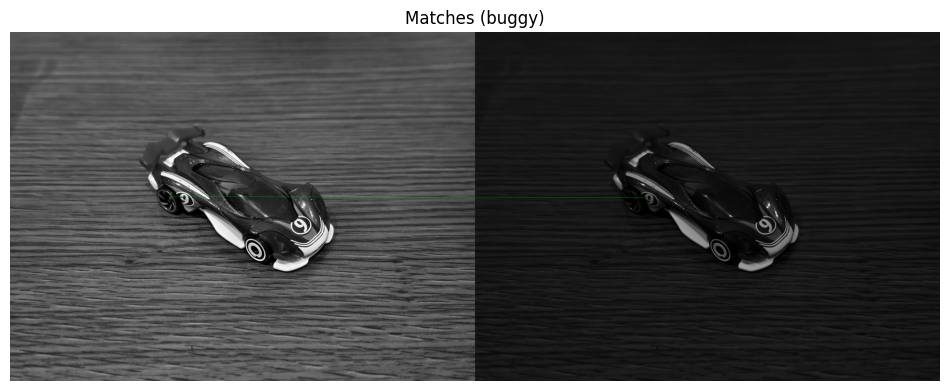

Fixed - Patch Descriptors
H: True inliers: 128 / 177


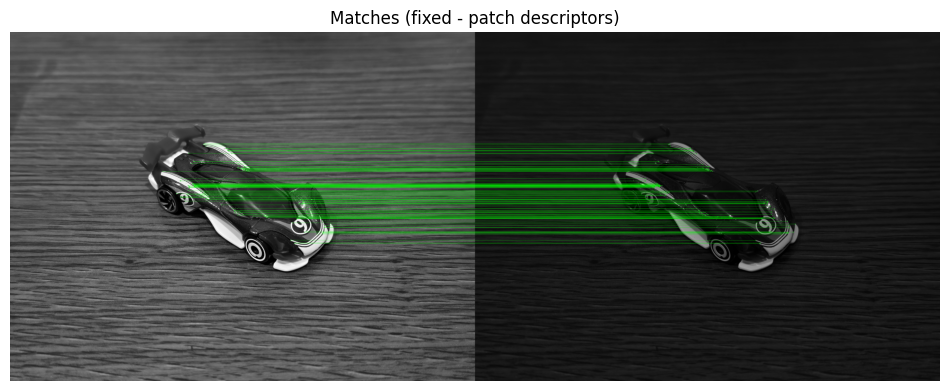

Fixed - HOG Descriptors
H: True inliers: 138 / 145


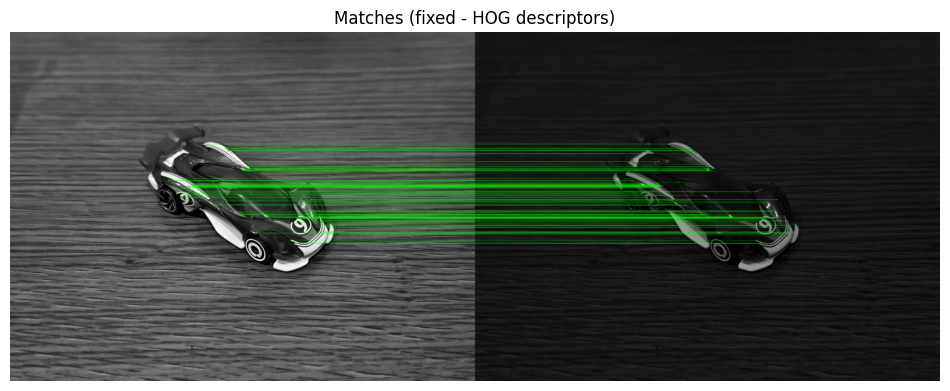

In [238]:
# Visualization
kpsA_f_buggy = kp_subset(kpsA_buggy, idxA_buggy)
kpsB_f_buggy = kp_subset(kpsB_buggy, idxB_buggy)

kpsA_f = kp_subset(kpsA, idxA)
kpsB_f = kp_subset(kpsB, idxB)

kpsA_f_hog = kp_subset(kpsA, idxA_hog)
kpsB_f_hog = kp_subset(kpsB, idxB_hog)

print("Buggy")
H, mask = ransac_homography_buggy(kpsA_f_buggy, kpsB_f_buggy, matchesA_buggy, reproj=0.8, maxIters=80)
print("H:", H is not None, "inliers:", int(mask.sum()) if mask is not None else 0, "/", len(matchesA_buggy))

vis_matches_buggy = cv2.drawMatches(
    A1, kpsA_f_buggy, 
    B1, kpsB_f_buggy, 
    matchesA_buggy, None,
    matchColor=[0, 255, 0],
    singlePointColor=[255, 0, 0],
    matchesMask=(mask.ravel().tolist() if mask is not None else None),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(12, 6))
plt.title("Matches (buggy)")
plt.imshow(vis_matches_buggy)
plt.axis('off')
plt.show()


print("Fixed - Patch Descriptors")
H, mask = ransac_homography(kpsA_f, kpsB_f, matchesA_patches, reproj=4.0, maxIters=2000)
print("H:", H is not None, "inliers:", int(mask.sum()) if mask is not None else 0, "/", len(matchesA_patches))

vis_matches_patches = cv2.drawMatches(
    A1, kpsA_f,
    B1, kpsB_f,
    matchesA_patches, None,
    matchColor=[0, 255, 0],
    singlePointColor=[255, 0, 0],
    matchesMask=(mask.ravel().tolist() if mask is not None else None),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(12, 6))
plt.title("Matches (fixed - patch descriptors)")
plt.imshow(vis_matches_patches)
plt.axis('off')
plt.show()


print("Fixed - HOG Descriptors")
H, mask = ransac_homography(kpsA_f_hog, kpsB_f_hog, matchesA_hog, reproj=4.0, maxIters=2000)
print("H:", H is not None, "inliers:", int(mask.sum()) if mask is not None else 0, "/", len(matchesA_hog))

vis_matches_hog = cv2.drawMatches(
    A1, kpsA_f_hog,
    B1, kpsB_f_hog,
    matchesA_hog, None,
    matchColor=[0, 255, 0],
    singlePointColor=[255, 0, 0],
    matchesMask=(mask.ravel().tolist() if mask is not None else None),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(12, 6))
plt.title("Matches (fixed - HOG descriptors)")
plt.imshow(vis_matches_hog)
plt.axis('off')
plt.show()

## 9) Quick Check

### Pair B

Buggy
D_A2_buggy: (48, 121) D_B2_buggy: (20, 121)
matches A2 buggy: 4
H: False inliers: 0 / 4


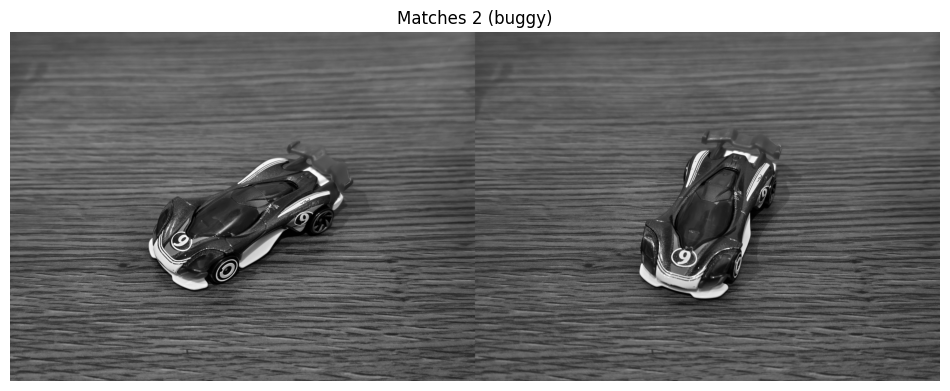


Fixed - Patch Descriptors
D_A2: (500, 121) D_B2: (500, 121)
matches A2 patches: 91
H: True inliers: 9 / 91


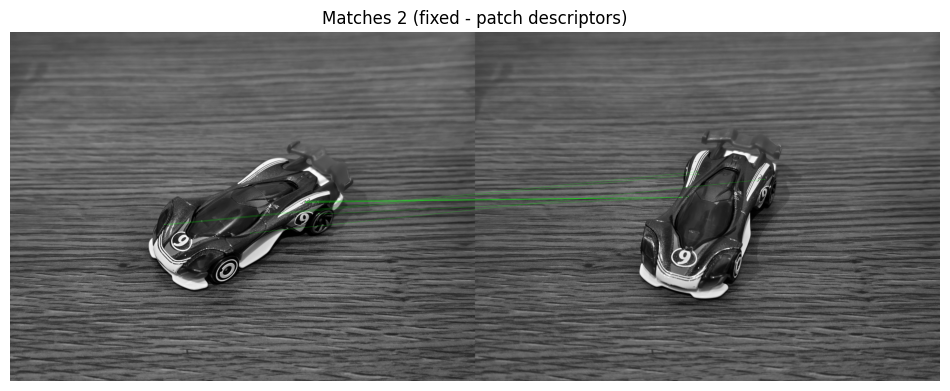


Fixed - HOG Descriptors
D_A2_hog: (500, 288) D_B2_hog: (500, 288)
matches A2 hog: 1
Not enough matches for RANSAC.
H: False inliers: 0 / 1


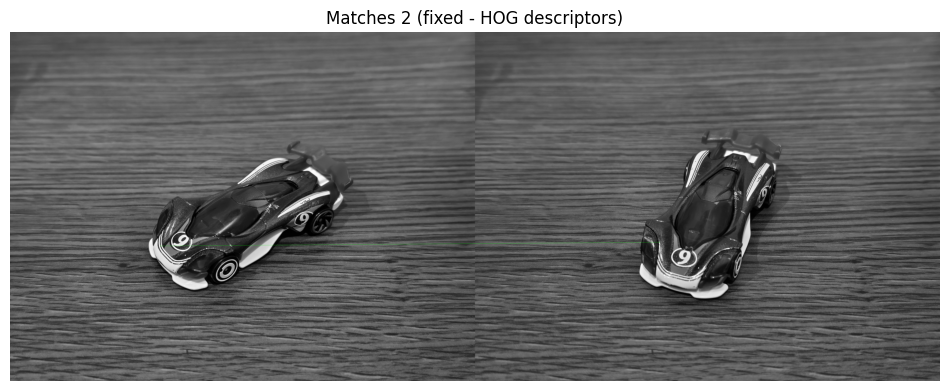

In [239]:
A2 = load_gray(IMG_A_2)
B2 = load_gray(IMG_B_2)

print("Buggy")

A2_smooth_buggy = convolve(A2, gaussian_kernel_buggy(7, 2.0))
B2_smooth_buggy = convolve(B2, gaussian_kernel_buggy(7, 2.0))

E_A2_buggy = canny_buggy(A2_smooth_buggy)
E_B2_buggy = canny_buggy(B2_smooth_buggy)

R_A2_buggy = harris_response_buggy(A2_smooth_buggy)
R_B2_buggy = harris_response_buggy(B2_smooth_buggy)

kpsA2_buggy = harris_kps_buggy(R_A2_buggy)
kpsB2_buggy = harris_kps_buggy(R_B2_buggy)

outA2_buggy = cv2.drawKeypoints(A2, kpsA2_buggy, None, color=(0, 0, 255), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
outB2_buggy = cv2.drawKeypoints(B2, kpsB2_buggy, None, color=(0, 0, 255), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

D_A2_buggy, idxA2_buggy = extract_patches_buggy(A2, kpsA2_buggy, patch=11)
D_B2_buggy, idxB2_buggy = extract_patches_buggy(B2, kpsB2_buggy, patch=11)
print("D_A2_buggy:", D_A2_buggy.shape, "D_B2_buggy:", D_B2_buggy.shape)

matchesA2_buggy = match_ratio_buggy(D_A2_buggy, D_B2_buggy, ratio=0.6)
print("matches A2 buggy:", len(matchesA2_buggy))

kpsA2_f_buggy = kp_subset(kpsA2_buggy, idxA2_buggy)
kpsB2_f_buggy = kp_subset(kpsB2_buggy, idxB2_buggy)

H, mask = ransac_homography_buggy(kpsA2_f_buggy, kpsB2_f_buggy, matchesA2_buggy, reproj=0.8, maxIters=80)
print("H:", H is not None, "inliers:", int(mask.sum()) if mask is not None else 0, "/", len(matchesA2_buggy))
vis_matches2_buggy = cv2.drawMatches(
    A2, kpsA2_f_buggy, 
    B2, kpsB2_f_buggy, 
    matchesA2_buggy, None,
    matchColor=[0, 255, 0],
    singlePointColor=[255, 0, 0],
    matchesMask=(mask.ravel().tolist() if mask is not None else None),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(12, 6))
plt.title("Matches 2 (buggy)")
plt.imshow(vis_matches2_buggy)
plt.axis('off')
plt.show()


print("\nFixed - Patch Descriptors")

A2_smooth = convolve(A2, gaussian_kernel(7, 2.0))
B2_smooth = convolve(B2, gaussian_kernel(7, 2.0))

R_A2 = harris_response(A2_smooth)
R_B2 = harris_response(B2_smooth)

kpsA2 = harris_kps(R_A2)
kpsB2 = harris_kps(R_B2)

D_A2, idxA2 = extract_patches(A2, kpsA2, patch=11)
D_B2, idxB2 = extract_patches(B2, kpsB2, patch=11)
print("D_A2:", D_A2.shape, "D_B2:", D_B2.shape)

matchesA2_patches = match_ratio(D_A2, D_B2, ratio=0.85)
print("matches A2 patches:", len(matchesA2_patches))

kpsA2_f = kp_subset(kpsA2, idxA2)
kpsB2_f = kp_subset(kpsB2, idxB2)

H2_patch, mask2_patch = ransac_homography(kpsA2_f, kpsB2_f, matchesA2_patches, reproj=4.0, maxIters=2000)
print("H:", H2_patch is not None, "inliers:", int(mask2_patch.sum()) if mask2_patch is not None else 0, "/", len(matchesA2_patches))

vis_matches2_patches = cv2.drawMatches(
    A2, kpsA2_f,
    B2, kpsB2_f,
    matchesA2_patches, None,
    matchColor=[0, 255, 0],
    singlePointColor=[255, 0, 0],
    matchesMask=(mask2_patch.ravel().tolist() if mask2_patch is not None else None),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(12, 6))
plt.title("Matches 2 (fixed - patch descriptors)")
plt.imshow(vis_matches2_patches)
plt.axis('off')
plt.show()


print("\nFixed - HOG Descriptors")

D_A2_hog, idxA2_hog = extract_hog(A2, kpsA2, patch=20, cell_size=5, bins=8)
D_B2_hog, idxB2_hog = extract_hog(B2, kpsB2, patch=20, cell_size=5, bins=8)
print("D_A2_hog:", D_A2_hog.shape, "D_B2_hog:", D_B2_hog.shape)

matchesA2_hog = match_ratio(D_A2_hog, D_B2_hog, ratio=0.75)
print("matches A2 hog:", len(matchesA2_hog))

kpsA2_f_hog = kp_subset(kpsA2, idxA2_hog)
kpsB2_f_hog = kp_subset(kpsB2, idxB2_hog)

H2_hog, mask2_hog = ransac_homography(kpsA2_f_hog, kpsB2_f_hog, matchesA2_hog, reproj=4.0, maxIters=2000)
print("H:", H2_hog is not None, "inliers:", int(mask2_hog.sum()) if mask2_hog is not None else 0, "/", len(matchesA2_hog))

vis_matches2_hog = cv2.drawMatches(
    A2, kpsA2_f_hog,
    B2, kpsB2_f_hog,
    matchesA2_hog, None,
    matchColor=[0, 255, 0],
    singlePointColor=[255, 0, 0],
    matchesMask=(mask2_hog.ravel().tolist() if mask2_hog is not None else None),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(12, 6))
plt.title("Matches 2 (fixed - HOG descriptors)")
plt.imshow(vis_matches2_hog)
plt.axis('off')
plt.show()

### Pair C

Buggy
D_A3_buggy: (36, 121) D_B3_buggy: (95, 121)
matches A3 buggy: 1
H: False inliers: 0 / 1


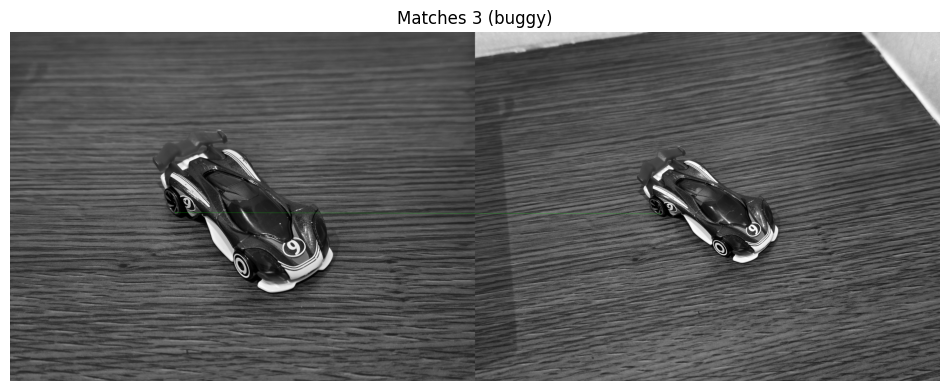


Fixed - Patch Descriptors
D_A3: (500, 121) D_B3: (500, 121)
matches A3 patches: 110
H: True inliers: 17 / 110


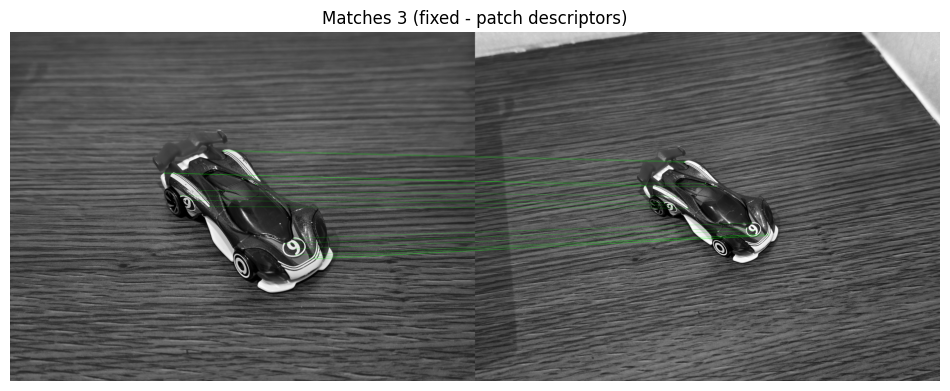


Fixed - HOG Descriptors
D_A3_hog: (500, 288) D_B3_hog: (500, 288)
matches A3 hog: 13
H: True inliers: 6 / 13


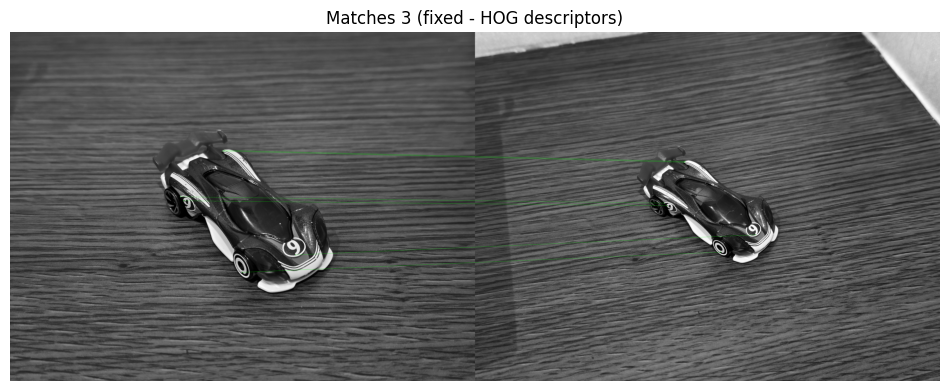

In [240]:
A3 = load_gray(IMG_A_3)
B3 = load_gray(IMG_B_3)

print("Buggy")

A3_smooth_buggy = convolve(A3, gaussian_kernel_buggy(7, 2.0))
B3_smooth_buggy = convolve(B3, gaussian_kernel_buggy(7, 2.0))

E_A3_buggy = canny_buggy(A3_smooth_buggy)
E_B3_buggy = canny_buggy(B3_smooth_buggy)

R_A3_buggy = harris_response_buggy(A3_smooth_buggy)
R_B3_buggy = harris_response_buggy(B3_smooth_buggy)

kpsA3_buggy = harris_kps_buggy(R_A3_buggy)
kpsB3_buggy = harris_kps_buggy(R_B3_buggy)

outA3_buggy = cv2.drawKeypoints(A3, kpsA3_buggy, None, color=(0, 0, 255), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
outB3_buggy = cv2.drawKeypoints(B3, kpsB3_buggy, None, color=(0, 0, 255), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

D_A3_buggy, idxA3_buggy = extract_patches_buggy(A3, kpsA3_buggy, patch=11)
D_B3_buggy, idxB3_buggy = extract_patches_buggy(B3, kpsB3_buggy, patch=11)
print("D_A3_buggy:", D_A3_buggy.shape, "D_B3_buggy:", D_B3_buggy.shape)

matchesA3_buggy = match_ratio_buggy(D_A3_buggy, D_B3_buggy, ratio=0.6)
print("matches A3 buggy:", len(matchesA3_buggy))

kpsA3_f_buggy = kp_subset(kpsA3_buggy, idxA3_buggy)
kpsB3_f_buggy = kp_subset(kpsB3_buggy, idxB3_buggy)

H, mask = ransac_homography_buggy(kpsA3_f_buggy, kpsB3_f_buggy, matchesA3_buggy, reproj=0.8, maxIters=80)
print("H:", H is not None, "inliers:", int(mask.sum()) if mask is not None else 0, "/", len(matchesA3_buggy))
vis_matches3_buggy = cv2.drawMatches(
    A3, kpsA3_f_buggy, 
    B3, kpsB3_f_buggy, 
    matchesA3_buggy, None,
    matchColor=[0, 255, 0],
    singlePointColor=[255, 0, 0],
    matchesMask=(mask.ravel().tolist() if mask is not None else None),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(12, 6))
plt.title("Matches 3 (buggy)")
plt.imshow(vis_matches3_buggy)
plt.axis('off')
plt.show()


print("\nFixed - Patch Descriptors")

A3_smooth = convolve(A3, gaussian_kernel(7, 2.0))
B3_smooth = convolve(B3, gaussian_kernel(7, 2.0))

R_A3 = harris_response(A3_smooth)
R_B3 = harris_response(B3_smooth)

kpsA3 = harris_kps(R_A3)
kpsB3 = harris_kps(R_B3)

D_A3, idxA3 = extract_patches(A3, kpsA3, patch=11)
D_B3, idxB3 = extract_patches(B3, kpsB3, patch=11)
print("D_A3:", D_A3.shape, "D_B3:", D_B3.shape)

matchesA3_patches = match_ratio(D_A3, D_B3, ratio=0.85)
print("matches A3 patches:", len(matchesA3_patches))

kpsA3_f = kp_subset(kpsA3, idxA3)
kpsB3_f = kp_subset(kpsB3, idxB3)

H3_patch, mask3_patch = ransac_homography(kpsA3_f, kpsB3_f, matchesA3_patches, reproj=4.0, maxIters=2000)
print("H:", H3_patch is not None, "inliers:", int(mask3_patch.sum()) if mask3_patch is not None else 0, "/", len(matchesA3_patches))

vis_matches3_patches = cv2.drawMatches(
    A3, kpsA3_f,
    B3, kpsB3_f,
    matchesA3_patches, None,
    matchColor=[0, 255, 0],
    singlePointColor=[255, 0, 0],
    matchesMask=(mask3_patch.ravel().tolist() if mask3_patch is not None else None),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(12, 6))
plt.title("Matches 3 (fixed - patch descriptors)")
plt.imshow(vis_matches3_patches)
plt.axis('off')
plt.show()


print("\nFixed - HOG Descriptors")

D_A3_hog, idxA3_hog = extract_hog(A3, kpsA3, patch=20, cell_size=5, bins=8)
D_B3_hog, idxB3_hog = extract_hog(B3, kpsB3, patch=20, cell_size=5, bins=8)
print("D_A3_hog:", D_A3_hog.shape, "D_B3_hog:", D_B3_hog.shape)

matchesA3_hog = match_ratio(D_A3_hog, D_B3_hog, ratio=0.75)
print("matches A3 hog:", len(matchesA3_hog))

kpsA3_f_hog = kp_subset(kpsA3, idxA3_hog)
kpsB3_f_hog = kp_subset(kpsB3, idxB3_hog)

H3_hog, mask3_hog = ransac_homography(kpsA3_f_hog, kpsB3_f_hog, matchesA3_hog, reproj=4.0, maxIters=2000)
print("H:", H3_hog is not None, "inliers:", int(mask3_hog.sum()) if mask3_hog is not None else 0, "/", len(matchesA3_hog))

vis_matches3_hog = cv2.drawMatches(
    A3, kpsA3_f_hog,
    B3, kpsB3_f_hog,
    matchesA3_hog, None,
    matchColor=[0, 255, 0],
    singlePointColor=[255, 0, 0],
    matchesMask=(mask3_hog.ravel().tolist() if mask3_hog is not None else None),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(12, 6))
plt.title("Matches 3 (fixed - HOG descriptors)")
plt.imshow(vis_matches3_hog)
plt.axis('off')
plt.show()

## 10) Question

### 3a. Before RANSAC Filtering

Keypoint A1: 500
Keypoint A2: 500
Keypoint B1: 500
Keypoint B2: 500
Keypoint C1: 500
Keypoint C2: 500

Matches Patch Descriptors):
matches A patch: 177
matches B patch: 91
matches C patch: 110

Descriptor shapes (Patch):
D_A1_patch: (500, 121) 
D_A2_patch: (500, 121)
D_B1_patch: (500, 121) 
D_B2_patch: (500, 121)
D_C1_patch: (500, 121) 
D_C2_patch: (500, 121)


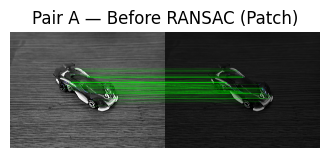

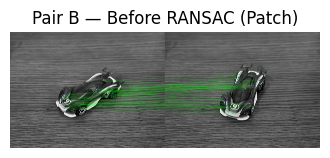

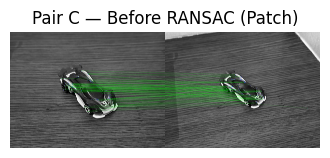

In [241]:
print("Keypoint A1:", len(kpsA))
print("Keypoint A2:", len(kpsA2))
print("Keypoint B1:", len(kpsB))
print("Keypoint B2:", len(kpsB2))
print("Keypoint C1:", len(kpsA3))
print("Keypoint C2:", len(kpsB3))

print("\nMatches Patch Descriptors):")
print("matches A patch:", len(matchesA_patches))
print("matches B patch:", len(matchesA2_patches))
print("matches C patch:", len(matchesA3_patches))

print("\nDescriptor shapes (Patch):")
print("D_A1_patch:", D_A.shape, "\nD_A2_patch:", D_B.shape)
print("D_B1_patch:", D_A2.shape, "\nD_B2_patch:", D_B2.shape)
print("D_C1_patch:", D_A3.shape, "\nD_C2_patch:", D_B3.shape)

# BEFORE RANSAC visualizations
vis_before_A_patch = cv2.drawMatches(
    A1, kpsA_f,
    B1, kpsB_f,
    matchesA_patches,
    None,
    matchColor=(0,255,0),
    singlePointColor=(255,0,0)
)

show(vis_before_A_patch, "Pair A — Before RANSAC (Patch)")

vis_before_B_patch = cv2.drawMatches(
    A2, kpsA2_f,
    B2, kpsB2_f,
    matchesA2_patches,
    None,
    matchColor=(0,255,0),
    singlePointColor=(255,0,0)
)

show(vis_before_B_patch, "Pair B — Before RANSAC (Patch)")

vis_before_C_patch = cv2.drawMatches(
    A3, kpsA3_f,
    B3, kpsB3_f,
    matchesA3_patches,
    None,
    matchColor=(0,255,0),
    singlePointColor=(255,0,0)
)

show(vis_before_C_patch, "Pair C — Before RANSAC (Patch)")

### 3b. Apply RANSAC-based Geometric Verification

Total matches: 177
RANSAC inliers: 128
Inlier ratio: 72.32%
Average reprojection error: 122.9605 pixels

Homography matrix H:
[[ 9.95143351e-01 -1.45869219e-03  4.53728022e+00]
 [-1.17374094e-03  9.96560954e-01  4.27854900e+00]
 [-9.56418479e-07 -7.46955862e-07  1.00000000e+00]]


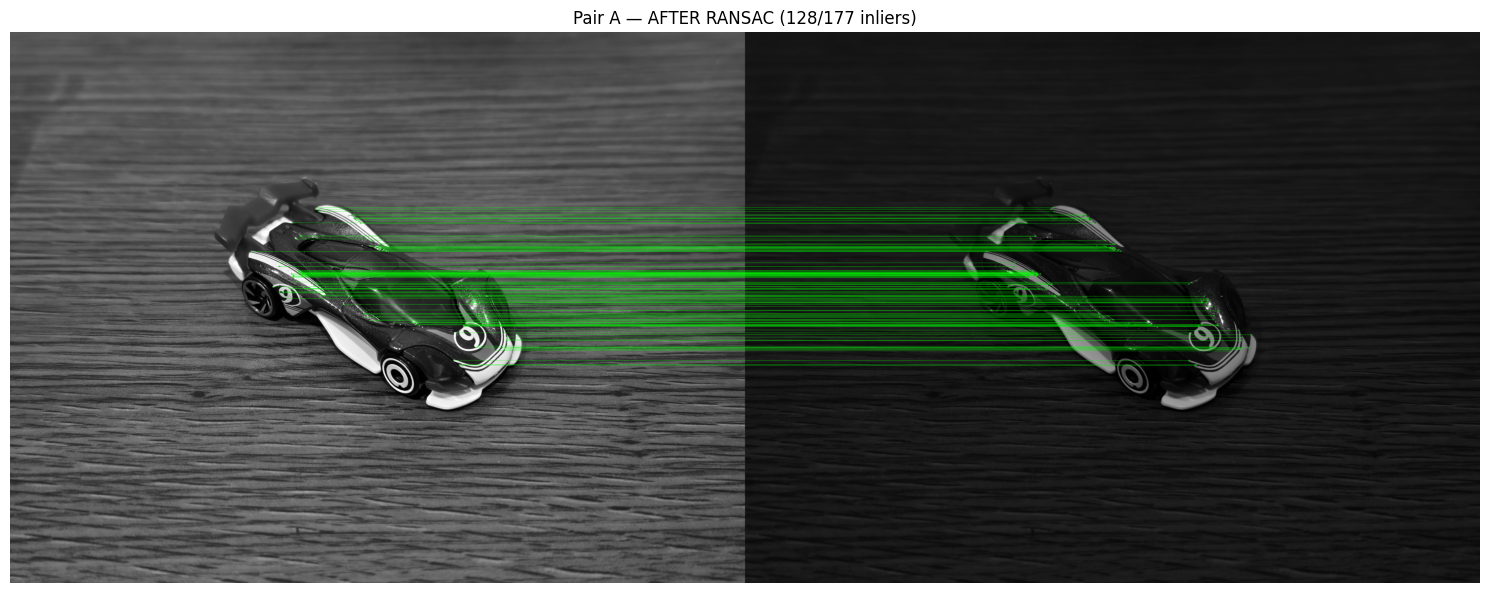



Total matches: 91
RANSAC inliers: 9
Inlier ratio: 9.89%
Average reprojection error: 833.3955 pixels

Homography matrix H:
[[ 1.26591061e-01 -1.02737838e+00  1.62480348e+03]
 [ 9.50918077e-02 -9.18123279e-01  1.46149907e+03]
 [ 6.29227653e-05 -6.23768575e-04  1.00000000e+00]]


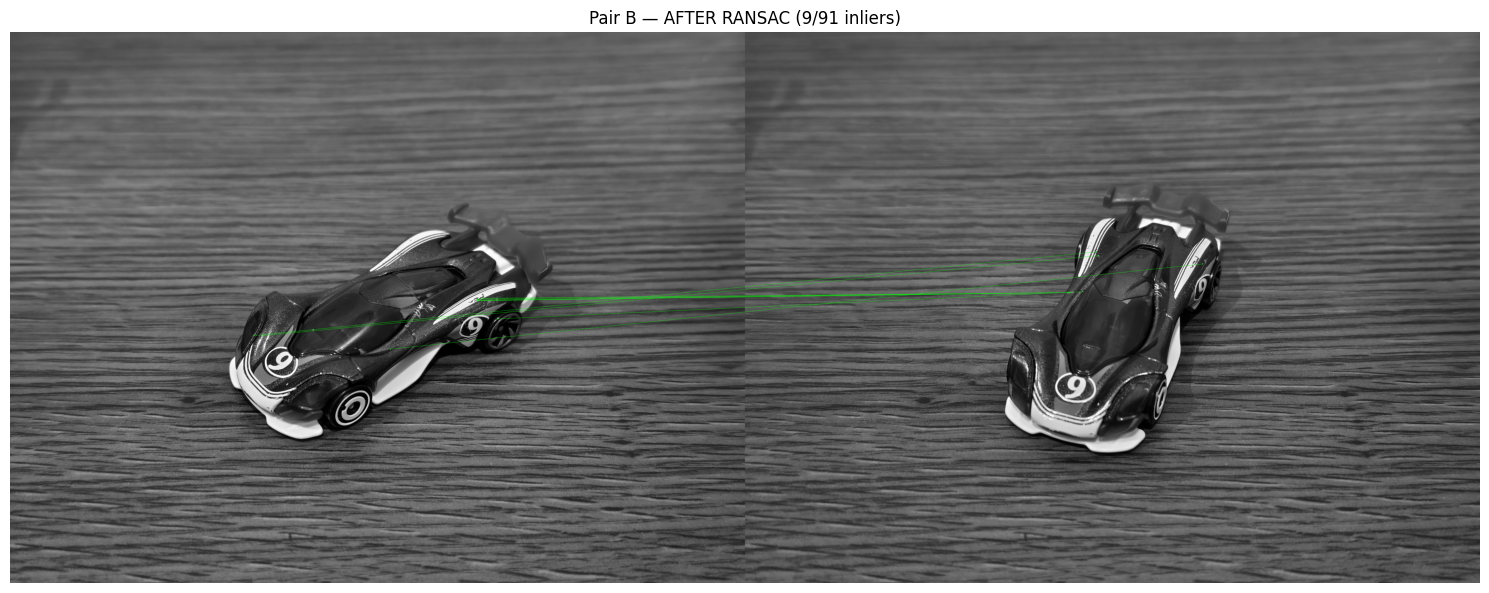



Total matches: 110
RANSAC inliers: 17
Inlier ratio: 15.45%
Average reprojection error: 267.1783 pixels

Homography matrix H:
[[ 1.04118474e+00  5.62101821e-01 -2.38703772e+02]
 [-4.12085521e-02  1.21244856e+00  2.36410873e+02]
 [ 5.61382853e-05  1.36424413e-04  1.00000000e+00]]


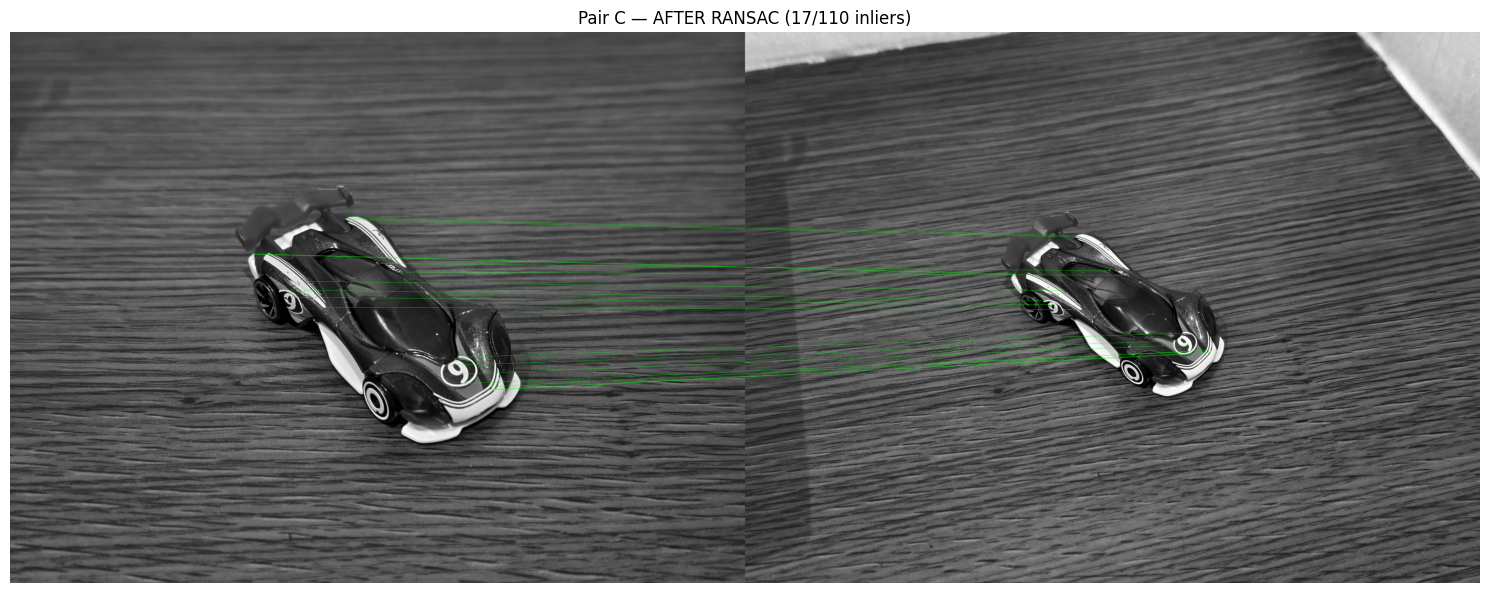

In [242]:
# Helper function to compute reprojection error
def compute_reprojection_error(H, pts1, pts2):
    """
    Compute average reprojection error for a homography.
    pts1, pts2: arrays of shape (N, 1, 2)
    """
    if H is None or len(pts1) == 0:
        return float('inf'), np.array([])
    
    # Transform points from image 1 using homography
    pts1_transformed = cv2.perspectiveTransform(pts1, H)
    
    # Compute Euclidean distance
    errors = np.linalg.norm(pts1_transformed - pts2, axis=2).flatten()
    
    return errors.mean(), errors


# Apply RANSAC
H_A, mask_A = ransac_homography(kpsA_f, kpsB_f, matchesA_patches, reproj=4.0, maxIters=2000)

if H_A is not None:
    inliers_A = mask_A.ravel().astype(bool)
    n_inliers_A = inliers_A.sum()
    
    # Get matched points
    pts_A1 = np.float32([kpsA_f[m.queryIdx].pt for m in matchesA_patches]).reshape(-1,1,2)
    pts_A2 = np.float32([kpsB_f[m.trainIdx].pt for m in matchesA_patches]).reshape(-1,1,2)
    
    # Compute reprojection error
    avg_reproj_error_A, errors_A = compute_reprojection_error(H_A, pts_A1, pts_A2)
    
    print(f"Total matches: {len(matchesA_patches)}")
    print(f"RANSAC inliers: {n_inliers_A}")
    print(f"Inlier ratio: {n_inliers_A/len(matchesA_patches)*100:.2f}%")
    print(f"Average reprojection error: {avg_reproj_error_A:.4f} pixels")
    print(f"\nHomography matrix H:")
    print(H_A)
else:
    print("RANSAC failed to find homography")
    n_inliers_A = 0
    avg_reproj_error_A = float('inf')

# Visualize AFTER RANSAC
vis_after_A = cv2.drawMatches(
    A1, kpsA_f,
    B1, kpsB_f,
    matchesA_patches, None,
    matchColor=(0, 255, 0),
    singlePointColor=(255, 0, 0),
    matchesMask=(mask_A.ravel().tolist() if mask_A is not None else None),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(15, 8))
plt.imshow(cv2.cvtColor(vis_after_A, cv2.COLOR_BGR2RGB))
plt.title(f"Pair A — AFTER RANSAC ({n_inliers_A}/{len(matchesA_patches)} inliers)")
plt.axis('off')
plt.tight_layout()
plt.show()

print("\n")


# Apply RANSAC
H_B, mask_B = ransac_homography(kpsA2_f, kpsB2_f, matchesA2_patches, reproj=4.0, maxIters=2000)

if H_B is not None:
    inliers_B = mask_B.ravel().astype(bool)
    n_inliers_B = inliers_B.sum()
    
    # Get matched points
    pts_B1 = np.float32([kpsA2_f[m.queryIdx].pt for m in matchesA2_patches]).reshape(-1,1,2)
    pts_B2 = np.float32([kpsB2_f[m.trainIdx].pt for m in matchesA2_patches]).reshape(-1,1,2)
    
    # Compute reprojection error
    avg_reproj_error_B, errors_B = compute_reprojection_error(H_B, pts_B1, pts_B2)
    
    print(f"Total matches: {len(matchesA2_patches)}")
    print(f"RANSAC inliers: {n_inliers_B}")
    print(f"Inlier ratio: {n_inliers_B/len(matchesA2_patches)*100:.2f}%")
    print(f"Average reprojection error: {avg_reproj_error_B:.4f} pixels")
    print(f"\nHomography matrix H:")
    print(H_B)
else:
    print("RANSAC failed to find homography")
    n_inliers_B = 0
    avg_reproj_error_B = float('inf')

# Visualize AFTER RANSAC
vis_after_B = cv2.drawMatches(
    A2, kpsA2_f,
    B2, kpsB2_f,
    matchesA2_patches, None,
    matchColor=(0, 255, 0),
    singlePointColor=(255, 0, 0),
    matchesMask=(mask_B.ravel().tolist() if mask_B is not None else None),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(15, 8))
plt.imshow(cv2.cvtColor(vis_after_B, cv2.COLOR_BGR2RGB))
plt.title(f"Pair B — AFTER RANSAC ({n_inliers_B}/{len(matchesA2_patches)} inliers)")
plt.axis('off')
plt.tight_layout()
plt.show()

print("\n")


# Apply RANSAC
H_C, mask_C = ransac_homography(kpsA3_f, kpsB3_f, matchesA3_patches, reproj=4.0, maxIters=2000)

if H_C is not None:
    inliers_C = mask_C.ravel().astype(bool)
    n_inliers_C = inliers_C.sum()
    
    # Get matched points
    pts_C1 = np.float32([kpsA3_f[m.queryIdx].pt for m in matchesA3_patches]).reshape(-1,1,2)
    pts_C2 = np.float32([kpsB3_f[m.trainIdx].pt for m in matchesA3_patches]).reshape(-1,1,2)
    
    # Compute reprojection error
    avg_reproj_error_C, errors_C = compute_reprojection_error(H_C, pts_C1, pts_C2)
    
    print(f"Total matches: {len(matchesA3_patches)}")
    print(f"RANSAC inliers: {n_inliers_C}")
    print(f"Inlier ratio: {n_inliers_C/len(matchesA3_patches)*100:.2f}%")
    print(f"Average reprojection error: {avg_reproj_error_C:.4f} pixels")
    print(f"\nHomography matrix H:")
    print(H_C)
else:
    print("RANSAC failed to find homography")
    n_inliers_C = 0
    avg_reproj_error_C = float('inf')

# Visualize AFTER RANSAC
vis_after_C = cv2.drawMatches(
    A3, kpsA3_f,
    B3, kpsB3_f,
    matchesA3_patches, None,
    matchColor=(0, 255, 0),
    singlePointColor=(255, 0, 0),
    matchesMask=(mask_C.ravel().tolist() if mask_C is not None else None),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(15, 8))
plt.imshow(cv2.cvtColor(vis_after_C, cv2.COLOR_BGR2RGB))
plt.title(f"Pair C — AFTER RANSAC ({n_inliers_C}/{len(matchesA3_patches)} inliers)")
plt.axis('off')
plt.tight_layout()
plt.show()

### 3c. Quantitative Measurements

In [243]:
import pandas as pd

results = {
    'Image Pair': ['Pair A (Illumination)', 'Pair B (Viewpoint)', 'Pair C (Scale)'],
    'Variation Type': ['Lighting change', 'Camera angle shift', 'Distance/Scale change'],
    'Total Keypoints (Img1)': [len(kpsA), len(kpsA2), len(kpsA3)],
    'Total Keypoints (Img2)': [len(kpsB), len(kpsB2), len(kpsB3)],
    'Initial Matches': [len(matchesA_patches), len(matchesA2_patches), len(matchesA3_patches)],
    'RANSAC Inliers': [n_inliers_A, n_inliers_B, n_inliers_C],
    'Inlier Ratio (%)': [
        f"{n_inliers_A/len(matchesA_patches)*100:.2f}" if len(matchesA_patches) > 0 else "0",
        f"{n_inliers_B/len(matchesA2_patches)*100:.2f}" if len(matchesA2_patches) > 0 else "0",
        f"{n_inliers_C/len(matchesA3_patches)*100:.2f}" if len(matchesA3_patches) > 0 else "0"
    ],
    'Avg Reprojection Error (px)': [
        f"{avg_reproj_error_A:.4f}",
        f"{avg_reproj_error_B:.4f}",
        f"{avg_reproj_error_C:.4f}"
    ],
    'Recognition Success': [
        'YES' if H_A is not None and n_inliers_A >= 10 else 'NO',
        'YES' if H_B is not None and n_inliers_B >= 10 else 'NO',
        'YES' if H_C is not None and n_inliers_C >= 10 else 'NO'
    ]
}

df_results = pd.DataFrame(results)

print(df_results.to_string(index=False))
print()

for pair_name, n_inliers, avg_error, total_matches in [
    ('Pair A (Illumination)', n_inliers_A, avg_reproj_error_A, len(matchesA_patches)),
    ('Pair B (Viewpoint)', n_inliers_B, avg_reproj_error_B, len(matchesA2_patches)),
    ('Pair C (Scale)', n_inliers_C, avg_reproj_error_C, len(matchesA3_patches))
]:
    print(f"{pair_name}:")
    print(f"  • Number of matched inliers: {n_inliers}")
    print(f"  • Average reprojection error: {avg_error:.4f} pixels")
    if total_matches > 0:
        print(f"  • Inlier ratio: {n_inliers/total_matches*100:.2f}%")
    print(f"  • Recognition success: {'YES - Scene correctly identified' if n_inliers >= 10 else 'NO - Insufficient inliers'}")
    print()

           Image Pair        Variation Type  Total Keypoints (Img1)  Total Keypoints (Img2)  Initial Matches  RANSAC Inliers Inlier Ratio (%) Avg Reprojection Error (px) Recognition Success
Pair A (Illumination)       Lighting change                     500                     500              177             128            72.32                    122.9605                 YES
   Pair B (Viewpoint)    Camera angle shift                     500                     500               91               9             9.89                    833.3955                  NO
       Pair C (Scale) Distance/Scale change                     500                     500              110              17            15.45                    267.1783                 YES

Pair A (Illumination):
  • Number of matched inliers: 128
  • Average reprojection error: 122.9605 pixels
  • Inlier ratio: 72.32%
  • Recognition success: YES - Scene correctly identified

Pair B (Viewpoint):
  • Number of matched inliers

In [244]:

# Pair A - HOG
H_A_hog, mask_A_hog = ransac_homography(kpsA_f_hog, kpsB_f_hog, matchesA_hog, reproj=4.0, maxIters=2000)
if H_A_hog is not None and mask_A_hog is not None:
    n_inliers_A_hog = mask_A_hog.ravel().sum()
    pts_A1_hog = np.float32([kpsA_f_hog[m.queryIdx].pt for m in matchesA_hog]).reshape(-1,1,2)
    pts_A2_hog = np.float32([kpsB_f_hog[m.trainIdx].pt for m in matchesA_hog]).reshape(-1,1,2)
    avg_reproj_error_A_hog, _ = compute_reprojection_error(H_A_hog, pts_A1_hog, pts_A2_hog)
else:
    n_inliers_A_hog = 0
    avg_reproj_error_A_hog = float('inf')

print(f"Pair A HOG: {n_inliers_A_hog}/{len(matchesA_hog)} inliers")

# Pair B - HOG
H_B_hog, mask_B_hog = ransac_homography(kpsA2_f_hog, kpsB2_f_hog, matchesA2_hog, reproj=4.0, maxIters=2000)
if H_B_hog is not None and mask_B_hog is not None:
    n_inliers_B_hog = mask_B_hog.ravel().sum()
    pts_B1_hog = np.float32([kpsA2_f_hog[m.queryIdx].pt for m in matchesA2_hog]).reshape(-1,1,2)
    pts_B2_hog = np.float32([kpsB2_f_hog[m.trainIdx].pt for m in matchesA2_hog]).reshape(-1,1,2)
    avg_reproj_error_B_hog, _ = compute_reprojection_error(H_B_hog, pts_B1_hog, pts_B2_hog)
else:
    n_inliers_B_hog = 0
    avg_reproj_error_B_hog = float('inf')

print(f"Pair B HOG: {n_inliers_B_hog}/{len(matchesA2_hog)} inliers")

# Pair C - HOG
H_C_hog, mask_C_hog = ransac_homography(kpsA3_f_hog, kpsB3_f_hog, matchesA3_hog, reproj=4.0, maxIters=2000)
if H_C_hog is not None and mask_C_hog is not None:
    n_inliers_C_hog = mask_C_hog.ravel().sum()
    pts_C1_hog = np.float32([kpsA3_f_hog[m.queryIdx].pt for m in matchesA3_hog]).reshape(-1,1,2)
    pts_C2_hog = np.float32([kpsB3_f_hog[m.trainIdx].pt for m in matchesA3_hog]).reshape(-1,1,2)
    avg_reproj_error_C_hog, _ = compute_reprojection_error(H_C_hog, pts_C1_hog, pts_C2_hog)
else:
    n_inliers_C_hog = 0
    avg_reproj_error_C_hog = float('inf')

print(f"Pair C HOG: {n_inliers_C_hog}/{len(matchesA3_hog)} inliers")


Pair A HOG: 138/145 inliers
Not enough matches for RANSAC.
Pair B HOG: 0/1 inliers
Pair C HOG: 6/13 inliers


In [245]:
# STEP 2: Create comparison table

comparison_table = {
    'Image Pair': [
        'Pair A', 'Pair A',
        'Pair B', 'Pair B', 
        'Pair C', 'Pair C'
    ],
    'Descriptor': [
        'Patch (mean-std)', 'HOG',
        'Patch (mean-std)', 'HOG',
        'Patch (mean-std)', 'HOG'
    ],
    'Dim': [
        121, 288,
        121, 288,
        121, 288
    ],
    'Initial Matches': [
        len(matchesA_patches), len(matchesA_hog),
        len(matchesA2_patches), len(matchesA2_hog),
        len(matchesA3_patches), len(matchesA3_hog)
    ],
    'RANSAC Inliers': [
        n_inliers_A, n_inliers_A_hog,
        n_inliers_B, n_inliers_B_hog,
        n_inliers_C, n_inliers_C_hog
    ],
    'Inlier Ratio (%)': [
        f"{n_inliers_A/len(matchesA_patches)*100:.1f}" if len(matchesA_patches) > 0 else "0",
        f"{n_inliers_A_hog/len(matchesA_hog)*100:.1f}" if len(matchesA_hog) > 0 else "0",
        f"{n_inliers_B/len(matchesA2_patches)*100:.1f}" if len(matchesA2_patches) > 0 else "0",
        f"{n_inliers_B_hog/len(matchesA2_hog)*100:.1f}" if len(matchesA2_hog) > 0 else "0",
        f"{n_inliers_C/len(matchesA3_patches)*100:.1f}" if len(matchesA3_patches) > 0 else "0",
        f"{n_inliers_C_hog/len(matchesA3_hog)*100:.1f}" if len(matchesA3_hog) > 0 else "0"
    ],
    'Reproj Error (px)': [
        f"{avg_reproj_error_A:.2f}" if avg_reproj_error_A != float('inf') else "N/A",
        f"{avg_reproj_error_A_hog:.2f}" if avg_reproj_error_A_hog != float('inf') else "N/A",
        f"{avg_reproj_error_B:.2f}" if avg_reproj_error_B != float('inf') else "N/A",
        f"{avg_reproj_error_B_hog:.2f}" if avg_reproj_error_B_hog != float('inf') else "N/A",
        f"{avg_reproj_error_C:.2f}" if avg_reproj_error_C != float('inf') else "N/A",
        f"{avg_reproj_error_C_hog:.2f}" if avg_reproj_error_C_hog != float('inf') else "N/A"
    ],
    'Success': [
        '✓' if n_inliers_A >= 10 else '✗',
        '✓' if n_inliers_A_hog >= 10 else '✗',
        '✓' if n_inliers_B >= 10 else '✗',
        '✓' if n_inliers_B_hog >= 10 else '✗',
        '✓' if n_inliers_C >= 10 else '✗',
        '✓' if n_inliers_C_hog >= 10 else '✗'
    ]
}

df_comparison = pd.DataFrame(comparison_table)


print(df_comparison.to_string(index=False))


Image Pair       Descriptor  Dim  Initial Matches RANSAC Inliers Inlier Ratio (%) Reproj Error (px) Success
    Pair A Patch (mean-std)  121              177            128             72.3            122.96       ✓
    Pair A              HOG  288              145            138             95.2             14.19       ✓
    Pair B Patch (mean-std)  121               91              9              9.9            833.40       ✗
    Pair B              HOG  288                1              0              0.0               N/A       ✗
    Pair C Patch (mean-std)  121              110             17             15.5            267.18       ✓
    Pair C              HOG  288               13              6             46.2            190.59       ✗
